# 🧮 El Álgebra del Significado: Experimentando con Embeddings

En este notebook exploraremos la propiedad más fascinante de los espacios de embeddings: **la composicionalidad lineal**.

Veremos cómo las relaciones semánticas (como el género o la realeza) se pueden calcular usando simples operaciones de vectores (suma y resta).

**Lo que haremos:**
1. Entender la Similitud Coseno (nuestra regla de medición).
2. Demostrar la famosa analogía `Rey - Hombre + Mujer = Reina` en un espacio controlado.
3. Entrenar un modelo Word2Vec real en segundos para ver cómo la red neuronal "descubre" estas relaciones por sí sola.

In [1]:
# Instalamos las dependencias necesarias (solo necesario en Colab)
!pip install gensim numpy matplotlib -q

import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec

# Configuración visual
plt.style.use('seaborn-v0_8-darkgrid')
print("¡Entorno listo! 🚀")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 29.2 MB/s eta 0:00:00
¡Entorno listo! 🚀


## 1. La Regla de Medición: Similitud Coseno

En un espacio de embeddings, no nos importa la distancia en línea recta (Euclidiana), sino el **ángulo** entre los vectores.
- Si el coseno es **1**, los vectores apuntan en la misma dirección (significado idéntico).
- Si es **0**, son ortogonales (no tienen relación).
- Si es **-1**, son opuestos.

In [2]:
def similitud_coseno(vec_a, vec_b):
    """Calcula la similitud coseno entre dos vectores numpy."""
    return np.dot(vec_a, vec_b) / (np.linalg.norm(vec_a) * np.linalg.norm(vec_b))

# Probemos con vectores aleatorios
v1 = np.array([1, 0, 0])
v2 = np.array([0, 1, 0]) # Ortogonal a v1
v3 = np.array([1, 1, 0]) # 45 grados de v1

print(f"Similitud entre v1 y v2 (Ortogonales): {similitud_coseno(v1, v2):.2f}")
print(f"Similitud entre v1 y v3 (45 grados):  {similitud_coseno(v1, v3):.2f}")
print(f"Similitud entre v1 y v1 (Idénticos):  {similitud_coseno(v1, v1):.2f}")

Similitud entre v1 y v2 (Ortogonales): 0.00
Similitud entre v1 y v3 (45 grados):  0.71
Similitud entre v1 y v1 (Idénticos):  1.00


## 2. La Magia: Rey - Hombre + Mujer = Reina

Para entender la álgebra, primero crearemos un **espacio semántico sintético en 2D**.
Imaginemos que el Eje X representa "Género" (-1 Mujer, +1 Hombre) y el Eje Y representa "Realeza" (0 Plebeyo, +1 Real).

Vector de Rey:    [1 1]
Vector de Hombre: [1 0]
Vector de Mujer:  [-1  0]
-----------------------------
Rey - Hombre + Mujer = [-1  1]
Vector de Reina real = [-1  1]
¿Coinciden? True


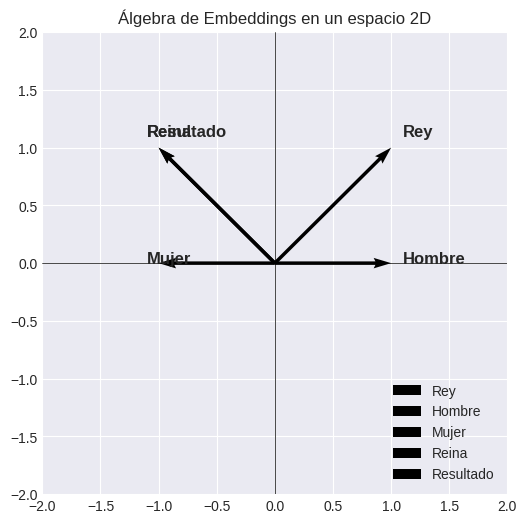

In [3]:
# Definimos nuestros vectores en un espacio 2D perfecto
# [Eje_X (Género), Eje_Y (Realeza)]
rey    = np.array([ 1,  1])  # Hombre, Real
hombre = np.array([ 1,  0])  # Hombre, Plebeyo
mujer  = np.array([-1,  0])  # Mujer, Plebeya
reina  = np.array([-1,  1])  # Mujer, Real

# ¡Hagamos la operación mágica!
resultado = rey - hombre + mujer

print(f"Vector de Rey:    {rey}")
print(f"Vector de Hombre: {hombre}")
print(f"Vector de Mujer:  {mujer}")
print(f"-----------------------------")
print(f"Rey - Hombre + Mujer = {resultado}")
print(f"Vector de Reina real = {reina}")
print(f"¿Coinciden? {np.array_equal(resultado, reina)}")

# Visualicémoslo
plt.figure(figsize=(6, 6))
palabras = {'Rey': rey, 'Hombre': hombre, 'Mujer': mujer, 'Reina': reina, 'Resultado': resultado}
for nombre, vec in palabras.items():
    plt.quiver(0, 0, vec[0], vec[1], angles='xy', scale_units='xy', scale=1, label=nombre)
    plt.text(vec[0]*1.1, vec[1]*1.1, nombre, fontsize=12, fontweight='bold')

plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.grid(True)
plt.title("Álgebra de Embeddings en un espacio 2D")
plt.legend()
plt.show()

## 3. En la Vida Real: Entrenando un Word2Vec

En la realidad, los espacios tienen 300 o 768 dimensiones y no los diseñamos a mano. La red neuronal los descubre sola leyendo texto.

Vamos a crear un corpus pequeño pero muy repetitivo sobre realeza y obligar a la red a aprender la relación.

In [4]:
# Creamos un corpus artificial diseñado para forzar la relación semántica
corpus = [
    "el rey es un hombre poderoso", "la reina es una mujer poderosa",
    "el rey gobierna el reino", "la reina gobierna el reino",
    "el principe es un hombre joven", "la princesa es una mujer joven",
    "hombre y mujer son humanos", "rey y reina son monarcas",
    "el rey hombre", "la reina mujer", "rey hombre corona", "reina mujer corona"
] * 50 # Repetimos para darle más peso a los patrones

# Tokenizamos (separamos por espacios)
tokenized_corpus = [texto.split() for texto in corpus]

# Entrenamos el modelo (vector_size pequeño para visualización, window=2)
modelo = Word2Vec(sentences=tokenized_corpus, vector_size=50, window=2, min_count=1, epochs=100)

print("✅ Modelo entrenado. Probando la analogía en la vida real...")

# La función most_similar de Gensim hace la matemática por nosotros
# positive: lo que sumamos, negative: lo que restamos
resultado_analogia = modelo.wv.most_similar(positive=['reina', 'hombre'], negative=['rey'], topn=3)

print("\nFórmula: Reina + Hombre - Rey")
print("Resultados más cercanos encontrados por la red neuronal:")
for palabra, similitud in resultado_analogia:
    print(f" - {palabra}: {similitud:.4f}")

✅ Modelo entrenado. Probando la analogía en la vida real...

Fórmula: Reina + Hombre - Rey
Resultados más cercanos encontrados por la red neuronal:
 - princesa: 0.6062
 - una: 0.6043
 - poderosa: 0.5955


### 🎯 Conclusión
Como puedes ver, la red neuronal **descubrió por sí sola** que la relación entre "Rey" y "Hombre" es matemáticamente equivalente a la relación entre "Reina" y "Mujer".

No le dimos reglas de gramática ni de género. Solo le dimos texto y la geometría del espacio de embeddings hizo el resto. Esto es la base de cómo los LLMs "entienden" el mundo.